# Experiment 5: Implementation of RNN for Text Generation

**Name:** ABHISHEK J
**Roll No:** 24BAD002

---


## Dataset
**Tiny Shakespeare** — a ~1MB corpus of Shakespeare's plays, a standard benchmark dataset for character/word-level language modeling and text generation. It is compact enough to train quickly while still containing rich, structured English text, making it ideal for this experiment.

---

## PART A: Dataset Preparation

In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002

import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)

I0000 00:00:1787546300.656782    1281 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787546300.739086    1281 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787546302.615915    1281 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
# Load the Tiny Shakespeare dataset
# (Same corpus distributed via Hugging Face's "tiny_shakespeare" dataset;
#  fetched here directly as raw text for a lightweight, dependency-free load.)

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
path = "tinyshakespeare.txt"
urllib.request.urlretrieve(url, path)

with open(path, "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total characters in dataset:", len(raw_text))
print("\nSample text:\n")
print(raw_text[:500])

Total characters in dataset: 1115394

Sample text:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
# Explore the dataset
lines = [l.strip() for l in raw_text.split("\n") if l.strip() != ""]
print("Total non-empty lines:", len(lines))
print("\nFirst 5 lines:")
for l in lines[:5]:
    print(" -", l)

Total non-empty lines: 32777

First 5 lines:
 - First Citizen:
 - Before we proceed any further, hear me speak.
 - All:
 - Speak, speak.
 - First Citizen:


In [ ]:
# For a manageable training time on CPU, use a subset of the corpus.
# (In a full-scale run, the entire corpus could be used with a GPU runtime.)
subset_lines = lines[:1200]
corpus_text = " ".join(subset_lines)

# Convert text to lowercase
corpus_text = corpus_text.lower()
print("Subset corpus length (characters):", len(corpus_text))
print("Sample:", corpus_text[:300])

Subset corpus length (characters): 39165
Sample: first citizen: before we proceed any further, hear me speak. all: speak, speak. first citizen: you are all resolved rather to die than to famish? all: resolved. resolved. first citizen: first, you know caius marcius is chief enemy to the people. all: we know't, we know't. first citizen: let us kill 


In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
# Tokenize the text into individual words and build the vocabulary
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(subset_lines)

vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)
print("Sample word index (first 10 tokens):")
for word, idx in list(tokenizer.word_index.items())[:10]:
    print(f"  {word}: {idx}")

Vocabulary size: 1788
Sample word index (first 10 tokens):
  <OOV>: 1
  the: 2
  you: 3
  to: 4
  and: 5
  i: 6
  of: 7
  a: 8
  in: 9
  that: 10


In [ ]:
# Generate input sequences for next-word prediction using n-gram sequences
input_sequences = []
for line in subset_lines:
    token_list = tokenizer.texts_to_sequences([line.lower()])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

print("Total input sequences generated:", len(input_sequences))
print("Example raw sequence:", input_sequences[5])

Total input sequences generated: 5941
Example raw sequence: [128, 21, 292, 145, 395, 99]


In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
# Apply sequence padding so all inputs are of equal length
max_sequence_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")

print("Max sequence length:", max_sequence_len)
print("Padded input sequences shape:", input_sequences.shape)

# Split into predictors (X) and label (y) -> last word of each sequence is the label
X = input_sequences[:, :-1]
labels = input_sequences[:, -1]
y = to_categorical(labels, num_classes=vocab_size)

print("X shape:", X.shape)
print("y shape:", y.shape)

Max sequence length: 12
Padded input sequences shape: (5941, 12)


X shape: (5941, 11)
y shape: (5941, 1788)


In [ ]:
# Split the prepared sequences into training and validation datasets
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 4752
Validation samples: 1189


## PART B: Implementing the RNN Model

In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
embedding_dim = 64
rnn_units = 128

model = Sequential([
    # Embedding layer converts word indices into dense vector representations
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=X.shape[1]),
    # Simple RNN layer learns sequential dependencies in the text
    SimpleRNN(rnn_units),
    # Dense output layer with Softmax activation for next-word prediction
    Dense(vocab_size, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## PART C: Comparison of Optimization Algorithms

In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
# Train the RNN model using the prepared training dataset and validate it
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=128,
    verbose=2
)

Epoch 1/25


38/38 - 3s - 67ms/step - accuracy: 0.0328 - loss: 6.8921 - val_accuracy: 0.0437 - val_loss: 6.4961


Epoch 2/25


38/38 - 1s - 21ms/step - accuracy: 0.0417 - loss: 6.3065 - val_accuracy: 0.0437 - val_loss: 6.6168


Epoch 3/25


...

38/38 - 1s - 16ms/step - accuracy: 0.2734 - loss: 3.7058 - val_accuracy: 0.0547 - val_loss: 7.1302


Epoch 24/25


38/38 - 1s - 17ms/step - accuracy: 0.3083 - loss: 3.5521 - val_accuracy: 0.0530 - val_loss: 7.1980


Epoch 25/25


38/38 - 1s - 16ms/step - accuracy: 0.3413 - loss: 3.4055 - val_accuracy: 0.0530 - val_loss: 7.2486


In [ ]:
# Record final training / validation accuracy and loss
final_train_acc = history.history["accuracy"][-1]
final_val_acc = history.history["val_accuracy"][-1]
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

print(f"Final Training Accuracy   : {final_train_acc:.4f}")
print(f"Final Validation Accuracy : {final_val_acc:.4f}")
print(f"Final Training Loss       : {final_train_loss:.4f}")
print(f"Final Validation Loss     : {final_val_loss:.4f}")

Final Training Accuracy   : 0.3413
Final Validation Accuracy : 0.0530
Final Training Loss       : 3.4055
Final Validation Loss     : 7.2486


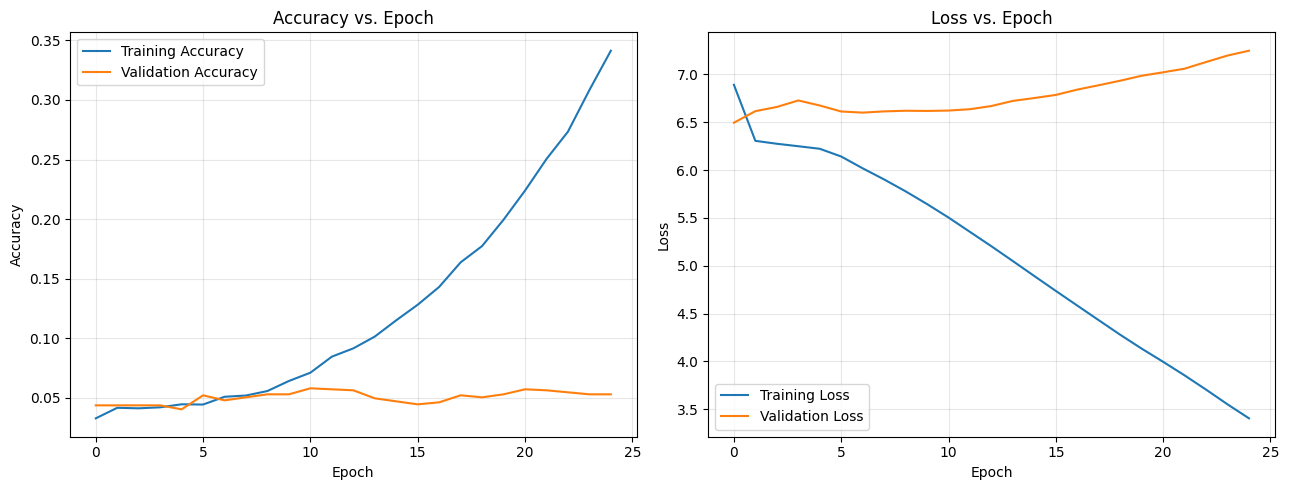

In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
# Visualize: Accuracy vs. Epoch and Loss vs. Epoch
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Accuracy vs. Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Loss vs. Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## PART D: Deep Learning Experiment Management (Text Generation)

In [ ]:
# Student Name: ABHISHEK J   Roll No: 24BAD002
def generate_text(seed_text, next_words, model, max_sequence_len, tokenizer):
    """Generate text by repeatedly predicting the next word given a seed."""
    result = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result.lower()])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding="pre")
        predicted_probs = model.predict(token_list, verbose=0)
        predicted_index = np.argmax(predicted_probs, axis=-1)[0]

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_index:
                output_word = word
                break
        if output_word == "":
            break
        result += " " + output_word
    return result

In [ ]:
# Provide seed words/sentences and generate multiple text samples
seed_texts = [
    "first citizen",
    "to be or not",
    "the king",
    "hear me speak"
]

for seed in seed_texts:
    generated = generate_text(seed, next_words=15, model=model,
                               max_sequence_len=max_sequence_len, tokenizer=tokenizer)
    print(f"Seed: '{seed}'")
    print(f"Generated: {generated}")
    print("-" * 70)

Seed: 'first citizen'
Generated: first citizen his dozen man fane task'd to mow cities ere allaying shadow beastly rebellion allaying rightly
----------------------------------------------------------------------


Seed: 'to be or not'
Generated: to be or not we have you are you are you are allaying able to rightly cushion as they
----------------------------------------------------------------------


Seed: 'the king'
Generated: the king of the gods o' the gods o' the gods o' the town is the gods
----------------------------------------------------------------------


Seed: 'hear me speak'
Generated: hear me speak be that you two wish your honours are so the beastly years summon the beastly
----------------------------------------------------------------------
